# 01 Exploratory Data Analysis

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

The dataset is the IBM HR Analytics Employee Attrition & Performance dataset from Kaggle (1,470 employees, 35 columns). It is synthetic, so the results say more about the modeling process than a real business case.

In [2]:
df = pd.read_csv("../data/raw/HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [4]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## Data cleaning

In [5]:
# Null values
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [6]:
# Negative values
(df.select_dtypes(include="number") < 0).any()

Age                         False
DailyRate                   False
DistanceFromHome            False
Education                   False
EmployeeCount               False
EmployeeNumber              False
EnvironmentSatisfaction     False
HourlyRate                  False
JobInvolvement              False
JobLevel                    False
JobSatisfaction             False
MonthlyIncome               False
MonthlyRate                 False
NumCompaniesWorked          False
PercentSalaryHike           False
PerformanceRating           False
RelationshipSatisfaction    False
StandardHours               False
StockOptionLevel            False
TotalWorkingYears           False
TrainingTimesLastYear       False
WorkLifeBalance             False
YearsAtCompany              False
YearsInCurrentRole          False
YearsSinceLastPromotion     False
YearsWithCurrManager        False
dtype: bool

> The cleaning helper function is in src/data_processor.py.

## Variable analysis

Numeric features will be stored in the `numeric_feats` variable.

In [7]:
df.select_dtypes(include="number").columns.size

26

In [8]:
numeric_feats = df.select_dtypes(include="number").columns.values

This list of ordinal features comes from dataset's documentation. They use a Likert scale, and the data dictionary is available [here](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset).

In [9]:
ordinal_feats = [
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobSatisfaction",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "WorkLifeBalance",
    "Education"
]

Ordinal features are removed from `numeric_feats` since their values are ordered categories rather than plain numeric values.

In [10]:
numeric_feats = list(set(numeric_feats) - set(ordinal_feats))

All `numeric_feats` are plotted by `"Attrition"`.

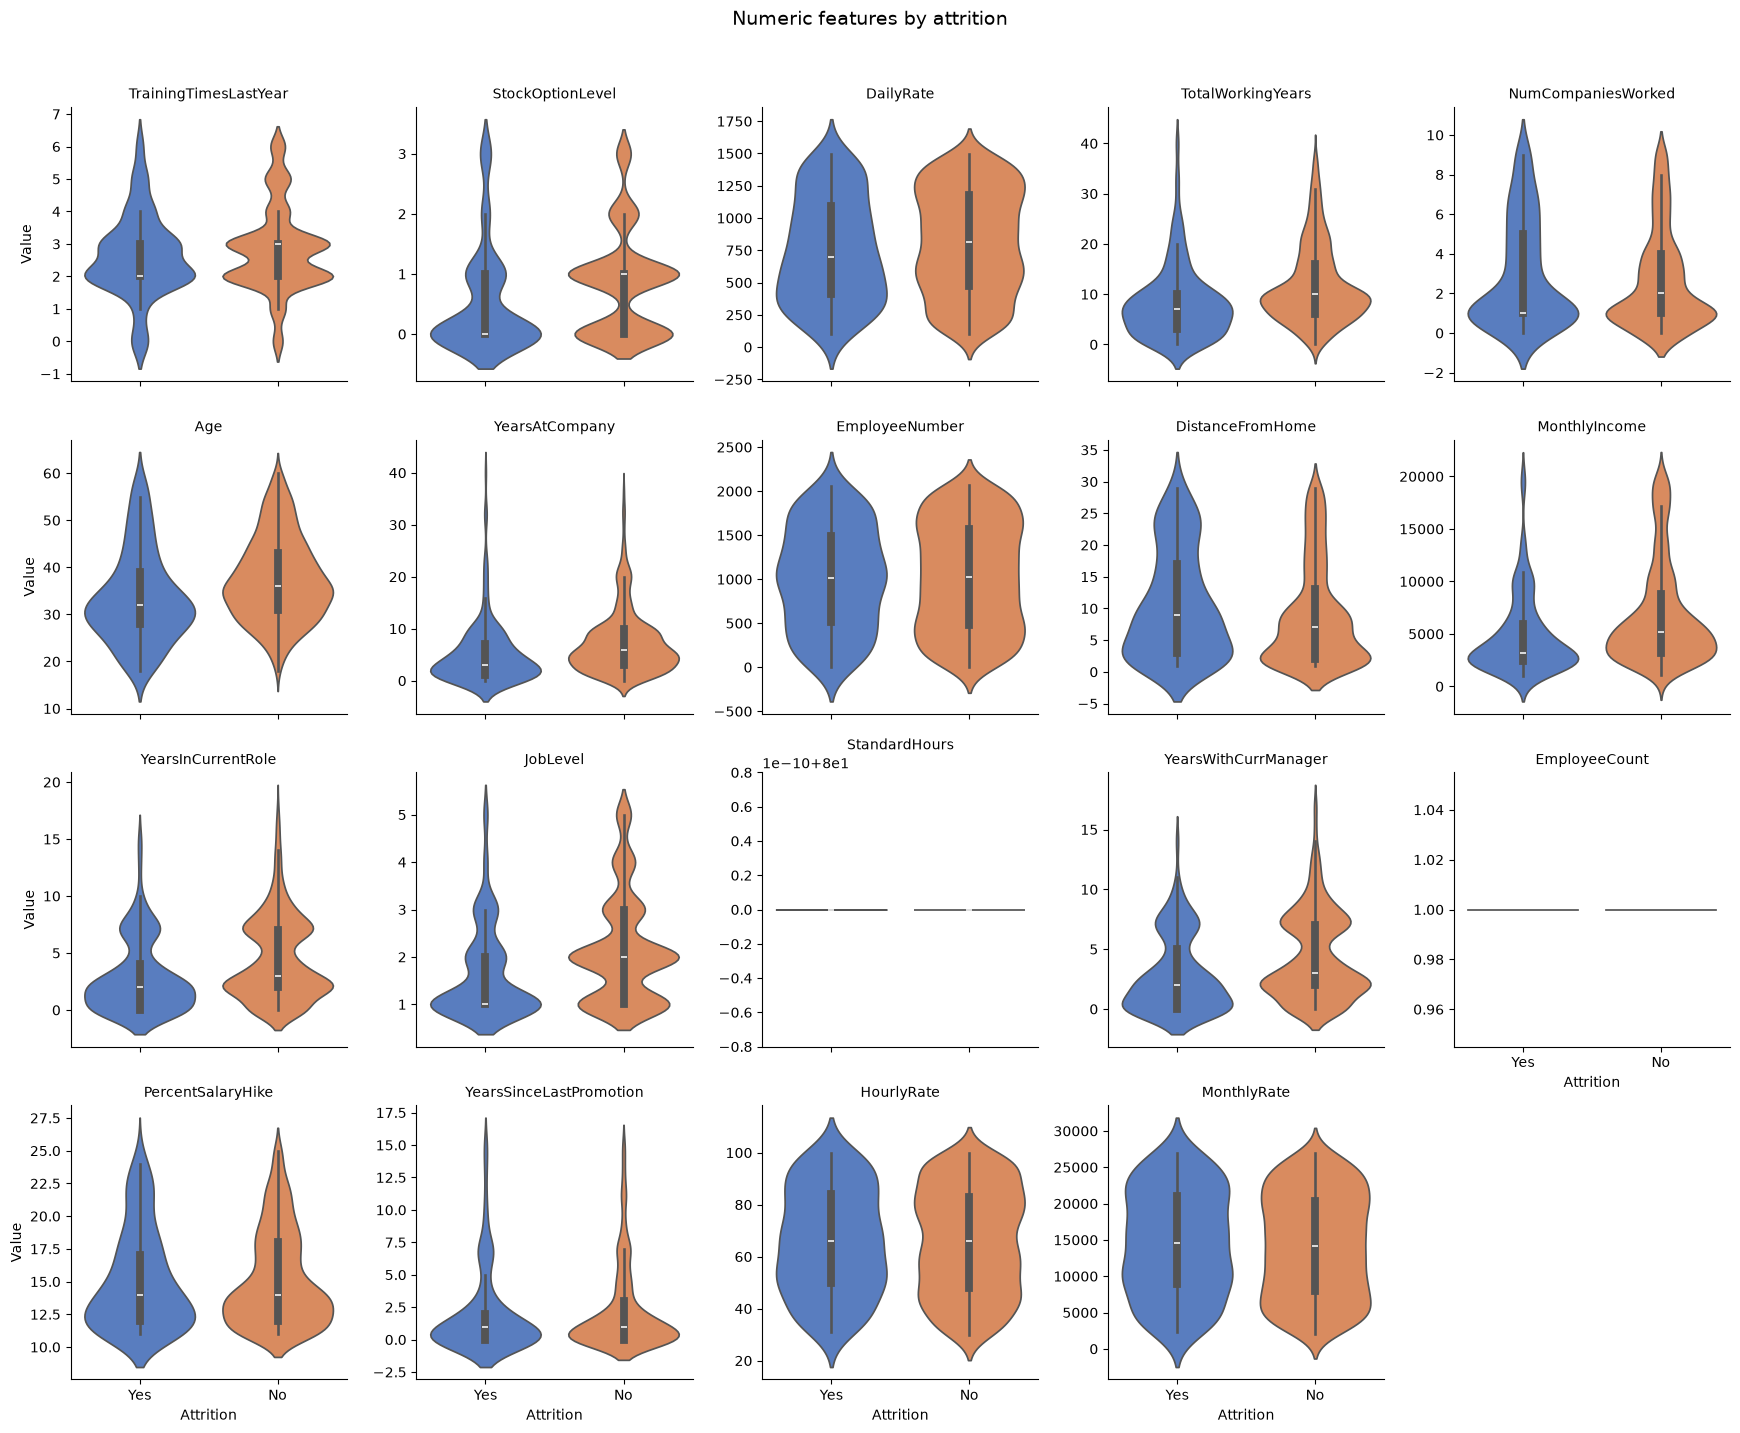

In [11]:
df_melt = df[numeric_feats + ["Attrition"]].melt(
    id_vars="Attrition", var_name="feature", value_name="value"
)

g = sns.catplot(
    data=df_melt,
    x="Attrition", y="value",
    col="feature", col_wrap=5,
    kind="violin",
    hue="Attrition",
    palette="muted",
    sharey=False,
    height=3.5, aspect=1
)

g.set_titles("{col_name}")
g.set_axis_labels("Attrition", "Value")
g.figure.suptitle("Numeric features by attrition", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In this dataset, `EmployeeCount` and `StandardHours` are constant. This will be taken into consideration since they carry no information for the models.

The following features stand out:
- `YearsSinceLastPromotion`: Attrited employees have a denser distribution for higher values.
- `TotalWorkingYears`: On average, retained employees have more total working years.
- `StockOptionLevel`: Typically, attrited employees don't have a stock option (0); otherwise, most retained employees have at least level 1.
- `YearsAtCompany`: Retained employees have longer tenure on average.
- `Age`: On average, retained employees are older.
- `DistanceFromHome`: The attrited group presents denser distribution for higher values.
- `YearsInCurrentRole`: On average, retained employees have more years in their current role.
- `NumCompaniesWorked`: Attrited employees present a denser distribution for higher values.
- `JobLevel`: Retained employees present a denser distribution for higher levels.
- `YearsWithCurrManager`: Attrited employees present a denser distribution for higher values.

In [12]:
df[ordinal_feats].describe()

,EnvironmentSatisfaction,JobInvolvement,JobSatisfaction,PerformanceRating,RelationshipSatisfaction,WorkLifeBalance,Education
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,2.721769,2.729932,2.728571,3.153741,2.712245,2.761224,2.912925
std,1.093082,0.711561,1.102846,0.360824,1.081209,0.706476,1.024165
min,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,4.000000,3.000000,4.000000,3.000000,4.000000,3.000000,4.000000
max,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000


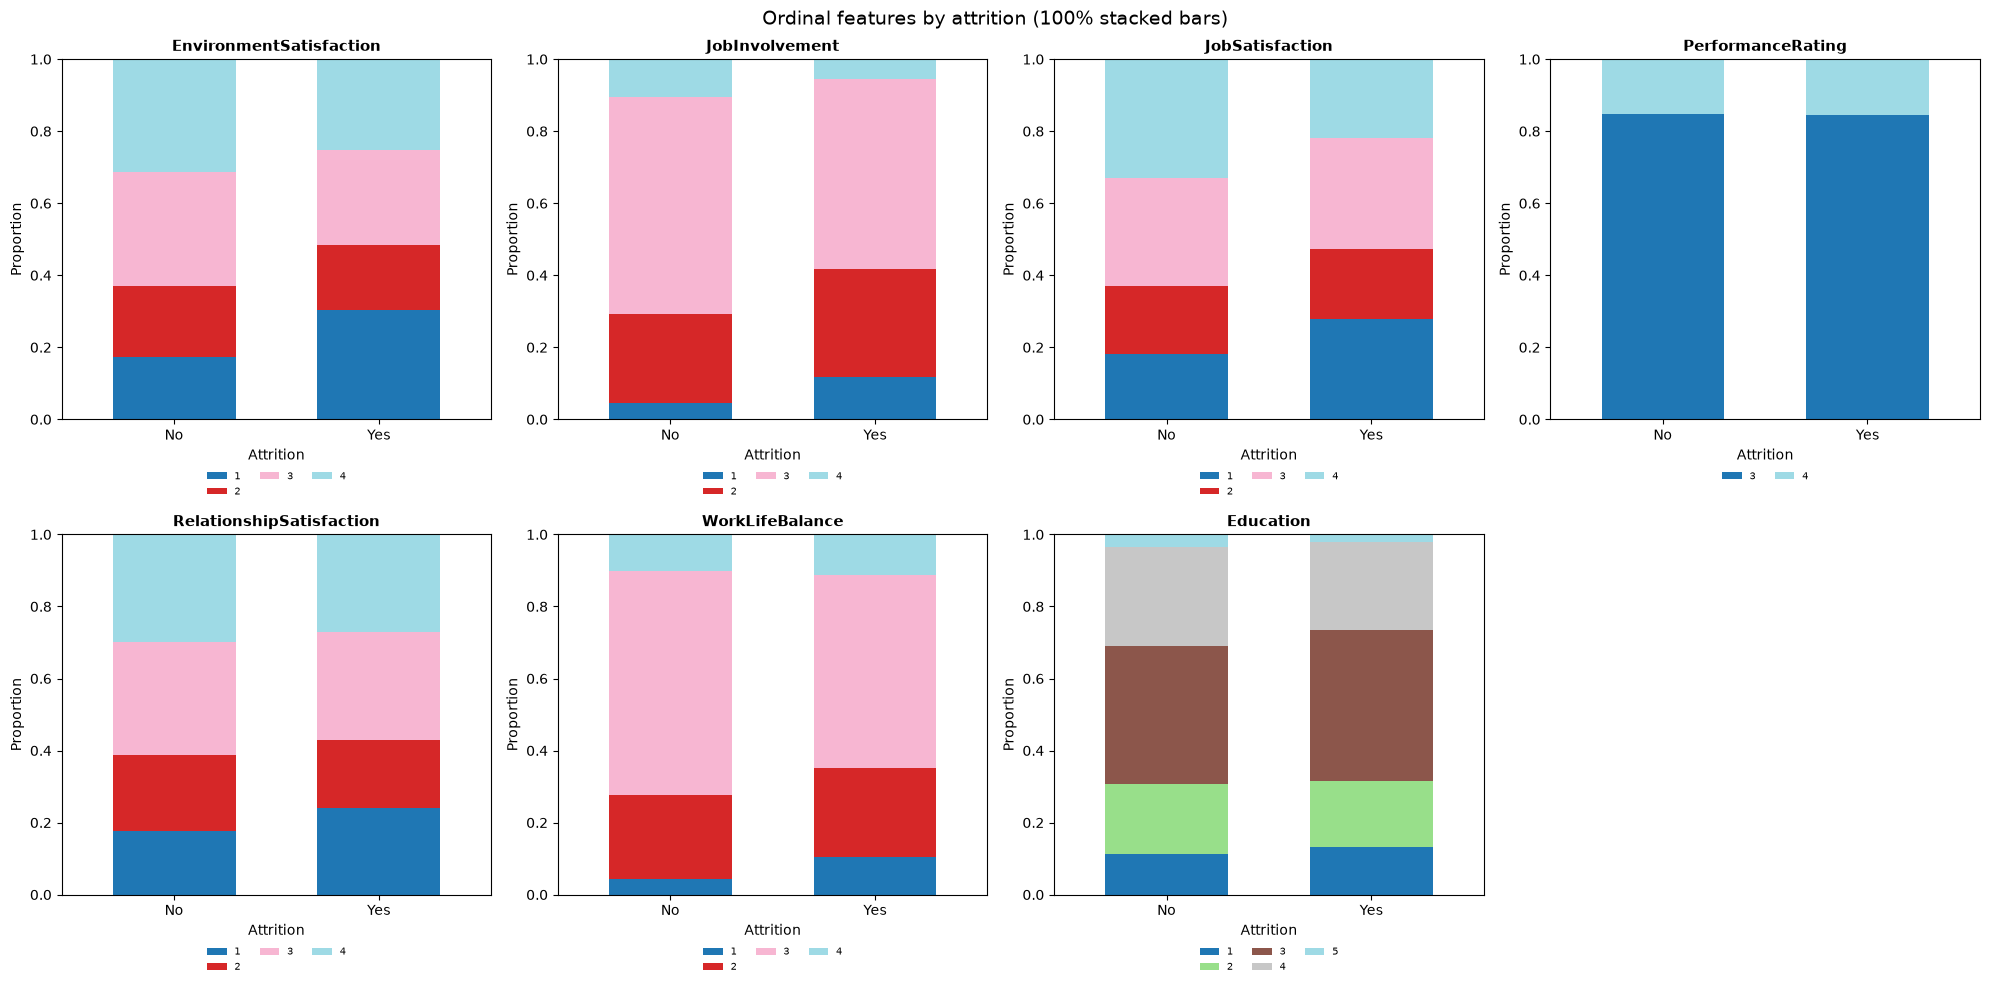

In [13]:
n_feats = len(ordinal_feats)
n_cols = 4
n_rows = math.ceil(n_feats / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten()

for i, feat in enumerate(ordinal_feats):
    ct = pd.crosstab(df["Attrition"], df[feat], normalize="index")

    ct.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        colormap="tab20",
        width=0.6,
        legend=False
    )

    axes[i].set_title(feat, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Attrition")
    axes[i].set_ylabel("Proportion")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=0)

    axes[i].legend(
        fontsize=7,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=min(len(ct.columns), 3),
        frameon=False
    )

for j in range(n_feats, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Ordinal features by attrition (100% stacked bars)", fontsize=14)
plt.tight_layout()
plt.show()

### Ordinal features

- `EnvironmentSatisfaction`: Retained employees show a higher proportion of 3 and 4; attrited employees, of 1.
- `JobInvolvement`: Typically, retained employees have a higher job involvement (options 3 and 4).
- `JobSatisfaction`: Higher proportion for option 4 in retained employees and higher proportion for option 1 (lower satisfaction) for attrited employees.
- `PerformanceRating`: Similar proportion for both groups.
- `RelationshipSatisfaction`: Nearly identical proportions. Attrited employees, on average, have a lower satisfaction (option 1).
- `WorkLifeBalance`: Attrited employees, on average, have a lower balance (options 1 and 2).
- `Education`: Higher proportion for option 3 in attrited employees and higher proportion in level 5 in retained employees.

In [14]:
df.select_dtypes(include="str").columns

Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18', 'OverTime'],
      dtype='str')

In [15]:
for col in df.select_dtypes(include="str").columns.values:
    print(df[col].value_counts())
    print(f"=================")

Attrition
No     1233
Yes     237
Name: count, dtype: int64
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
Gender
Male      882
Female    588
Name: count, dtype: int64
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64
MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64
Over18
Y    1470
Name: count,

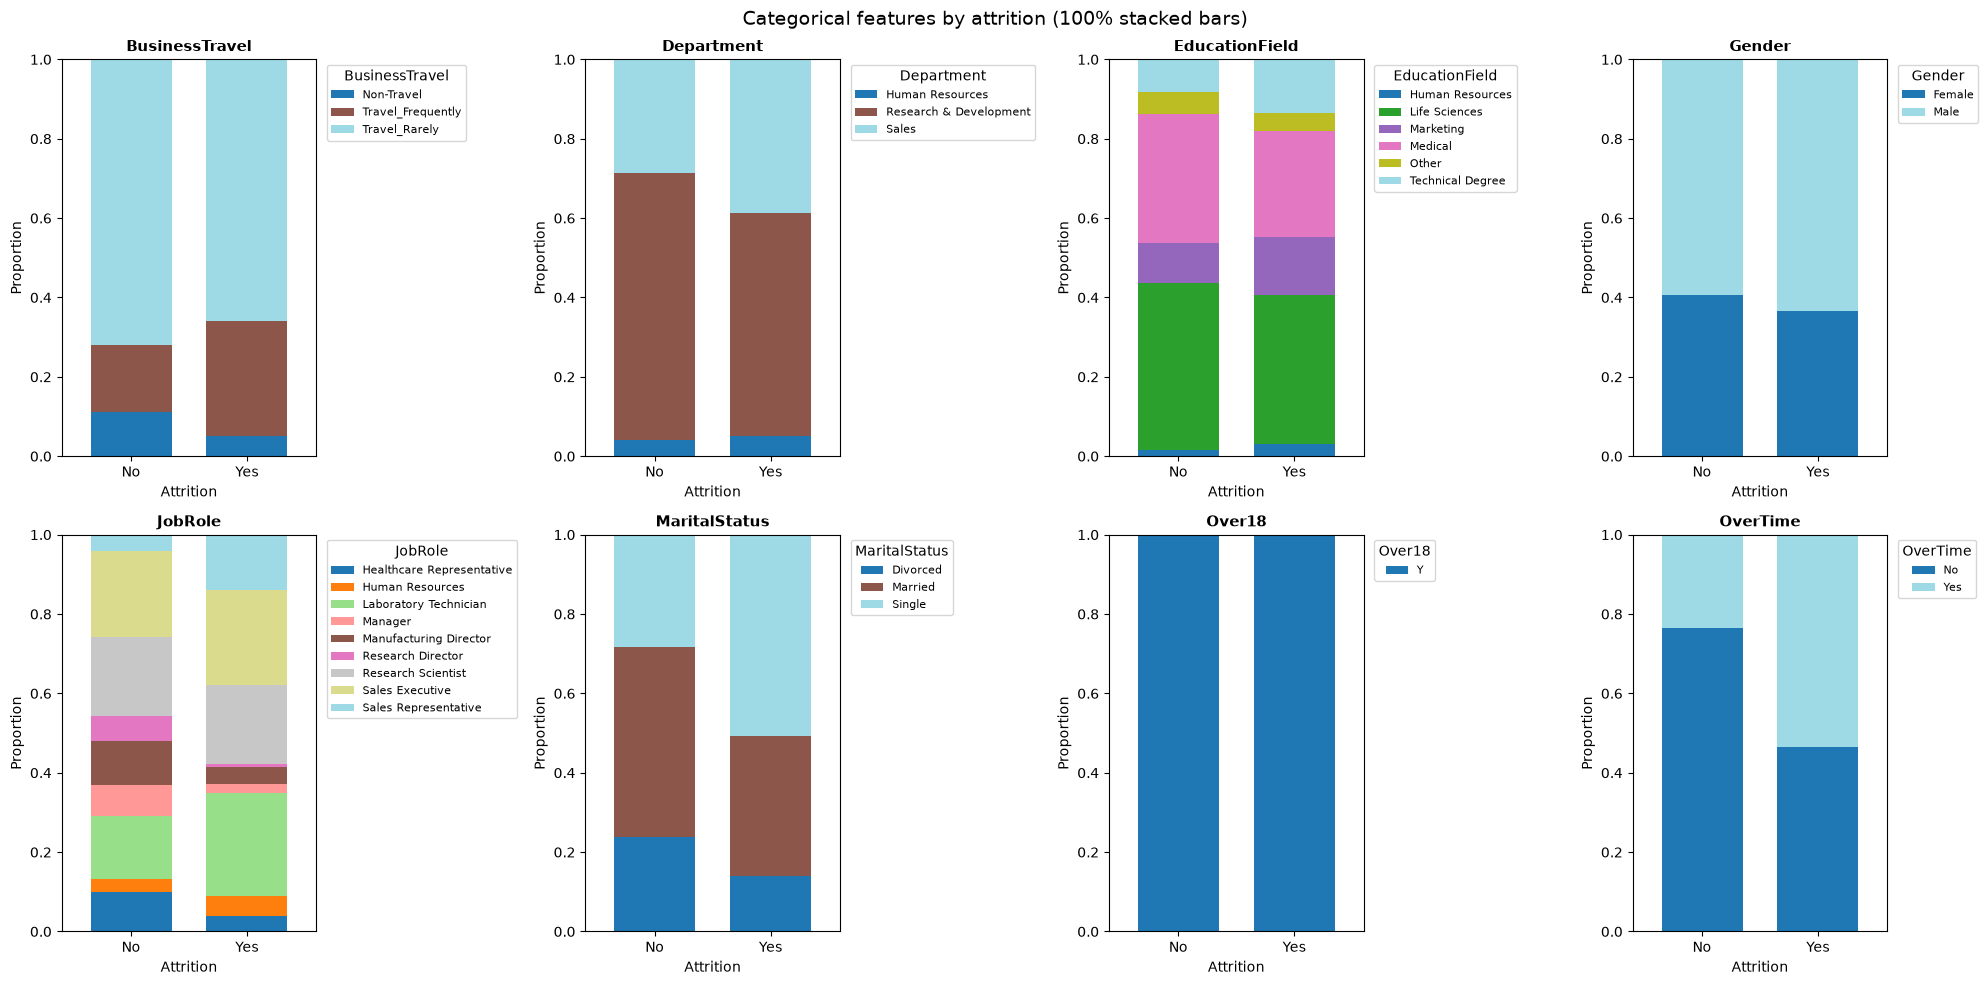

In [16]:
n_rows, n_cols = 2, 4

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten()

features = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "Over18",
    "OverTime",
]

for i, feat in enumerate(features):
    ct = pd.crosstab(df["Attrition"], df[feat], normalize="index")

    ct.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        colormap="tab20",
        width=0.7
    )

    axes[i].set_title(feat, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Attrition")
    axes[i].set_ylabel("Proportion")
    axes[i].set_ylim(0, 1)
    axes[i].legend(
        title=feat,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Categorical features by attrition (100% stacked bars)", fontsize=14)
plt.tight_layout()
plt.show()

### Categorical features

- `BusinessTravel`: On average, attrited employees travel more frequently.
- `Department`: Attrition is more common in Sales and Human Resources departments in this dataset.
- `EducationField`: On average, attrited employees are more frequent in technical and marketing fields.
- `Gender`: Similar distribution. This dataset presents more male employees.
- `JobRole`: Sales roles show higher attrition. Also, Laboratory Technician has a higher attrition ratio.
- `MaritalStatus`: Typically, single employees have attrited more.
- `Over18`: Constant value; it will be dropped before modeling.
- `OverTime`: Attrited employees, on average, have more overtime than retained employees.

## Variable correlation

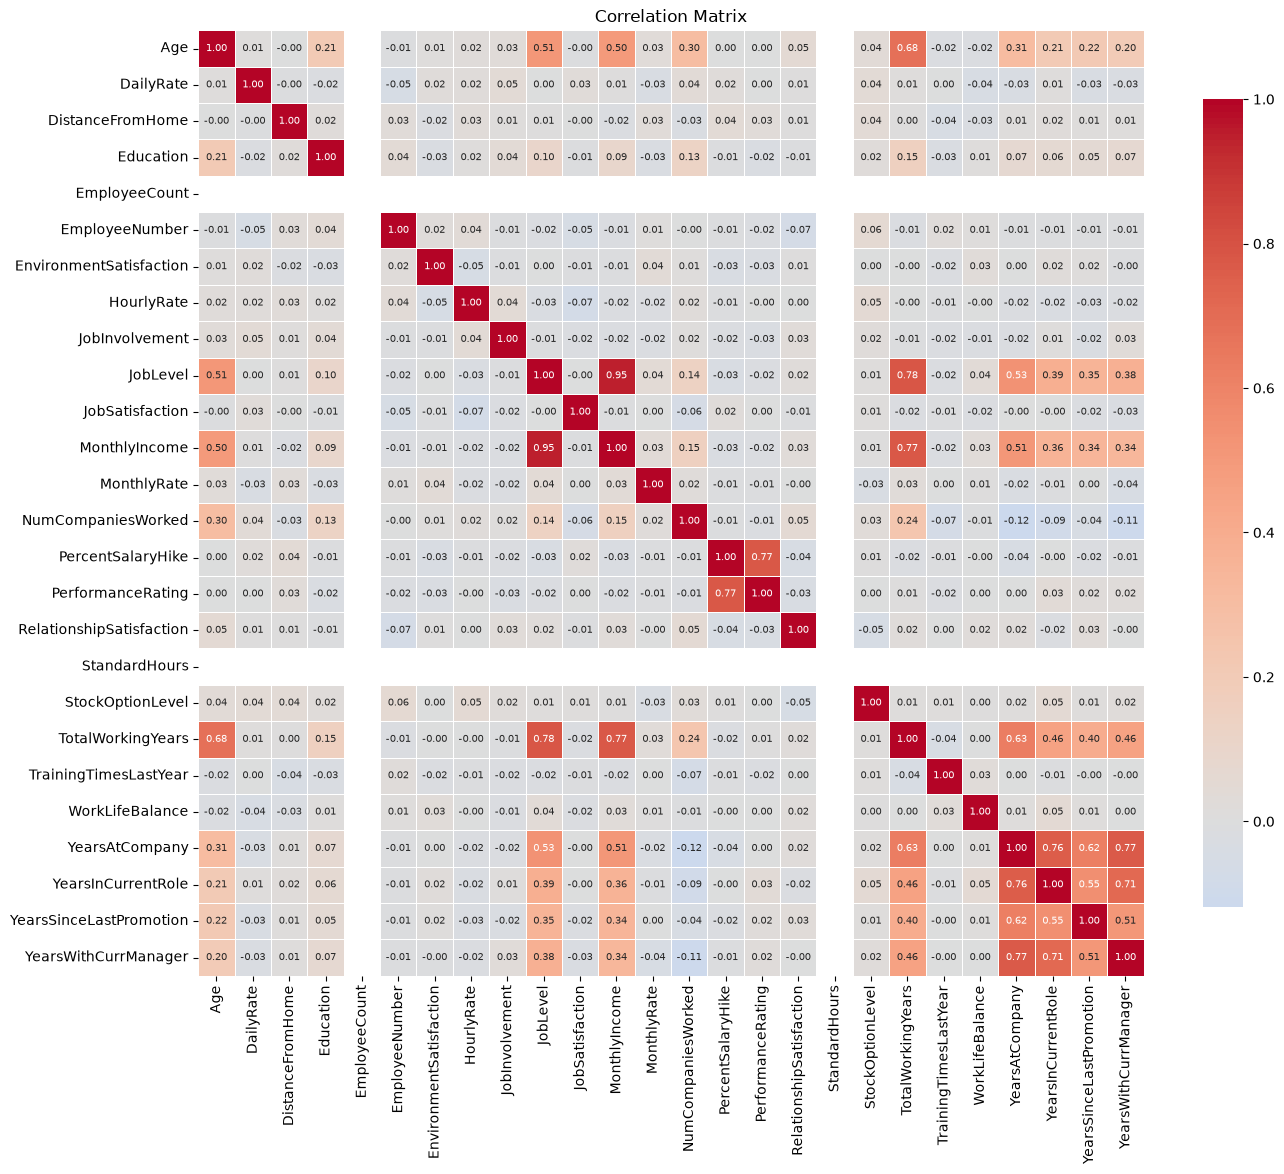

In [17]:
num_df = df.select_dtypes(include="number")

corr = num_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**Strong correlations (|r| ≥ 0.7)**

- **JobLevel ↔ MonthlyIncome**: 0.95
- **JobLevel ↔ TotalWorkingYears**: 0.78
- **MonthlyIncome ↔ TotalWorkingYears**: 0.77
- **YearsAtCompany ↔ YearsWithCurrManager**: 0.77
- **PercentSalaryHike ↔ PerformanceRating**: 0.77
- **YearsAtCompany ↔ YearsInCurrentRole**: 0.76
- **YearsInCurrentRole ↔ YearsWithCurrManager**: 0.71

**Moderate-to-high correlations (0.5 ≤ |r| < 0.7)**

- **Age ↔ TotalWorkingYears**: 0.68
- **TotalWorkingYears ↔ YearsAtCompany**: 0.63
- **YearsAtCompany ↔ YearsSinceLastPromotion**: 0.62
- **YearsInCurrentRole ↔ YearsSinceLastPromotion**: 0.55
- **JobLevel ↔ YearsAtCompany**: 0.53
- **Age ↔ JobLevel**: 0.51
- **MonthlyIncome ↔ YearsAtCompany**: 0.51
- **YearsSinceLastPromotion ↔ YearsWithCurrManager**: 0.51
- **Age ↔ MonthlyIncome**: 0.50

## VIF

In [18]:
X = num_df.drop(columns=["Attrition", "EmployeeCount", "StandardHours"], errors="ignore")
X = add_constant(X)

vif_data = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif_data = vif_data[vif_data["feature"] != "const"].sort_values("VIF", ascending=False)
vif_data

,feature,VIF
9,JobLevel,11.208731
11,MonthlyIncome,10.802169
18,TotalWorkingYears,4.767805
21,YearsAtCompany,4.587405
24,YearsWithCurrManager,2.774625
22,YearsInCurrentRole,2.718616
14,PercentSalaryHike,2.516413
15,PerformanceRating,2.514405
1,Age,2.044997
23,YearsSinceLastPromotion,1.674285


> Although `JobLevel` and `MonthlyIncome` show higher values (~11.2, ~10.8), the best model uses strong L2 regularization (`C=0.1`), which mitigates the multicollinearity (notebooks/02_modeling.ipynb).

## Summary

- `EmployeeCount`, `StandardHours` and `Over18` will be excluded from modeling since they have constant values.

- `EmployeeNumber` is an ID and has no predictive value. It will be dropped.

- `OverTime` and `Gender` will be converted to boolean. `Gender` will be renamed to `IsMale` (1 = male) since male employees are more frequent in this dataset specifically.

- An `OrdinalEncoder` is used only for `BusinessTravel`, since the other ordinal variables are already numeric (Likert).

- All numerical variables will be scaled with `StandardScaler`. Likert variables are scaled as well.

- All nominal (string) variables will be encoded with `OneHotEncoder` with `handle_unknown="ignore"`.